<a href="https://colab.research.google.com/github/anisha-dev26/BIS_LAB-1BF24CS054-/blob/main/CuckooSearch(EbgineeringDesign).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Generation   1 | Fitness (Cd): 0.02264718 | Violation: 0.00008525 | Feasible: False
Generation   2 | Fitness (Cd): 0.02264718 | Violation: 0.00009030 | Feasible: False
Generation   3 | Fitness (Cd): 0.02069928 | Violation: 0.00005157 | Feasible: False
Generation   4 | Fitness (Cd): 0.02069363 | Violation: 0.00000000 | Feasible: True
Generation   5 | Fitness (Cd): 0.02064649 | Violation: 0.00000000 | Feasible: True
Generation   6 | Fitness (Cd): 0.02058085 | Violation: 0.00000000 | Feasible: True
Generation   7 | Fitness (Cd): 0.02051036 | Violation: 0.00000000 | Feasible: True
Generation   8 | Fitness (Cd): 0.02048459 | Violation: 0.00000000 | Feasible: True
Generation   9 | Fitness (Cd): 0.02046131 | Violation: 0.00000000 | Feasible: True
Generation  10 | Fitness (Cd): 0.02046131 | Violation: 0.00000000 | Feasible: True
Generation  11 | Fitness (Cd): 0.02034074 | Violation: 0.00000000 | Feasible: True
Generation  12 | Fitness (Cd): 0.02034074 | Violation: 0.00000000 | Feasible: True
G

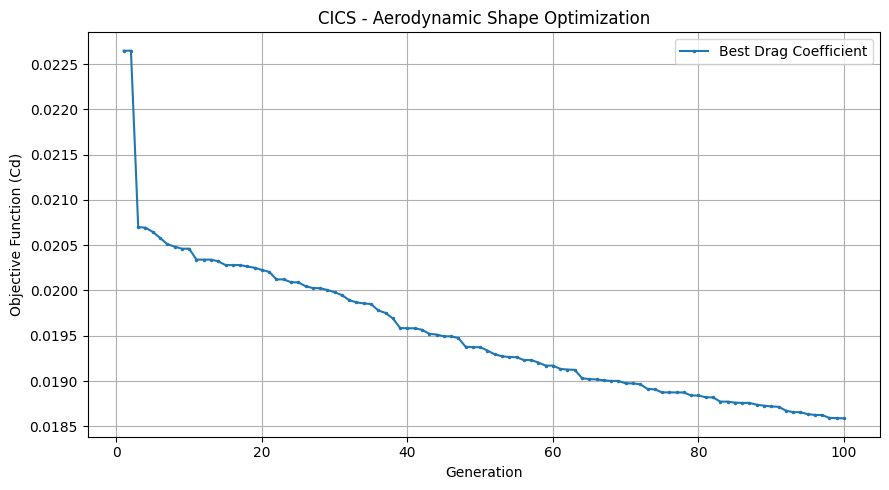

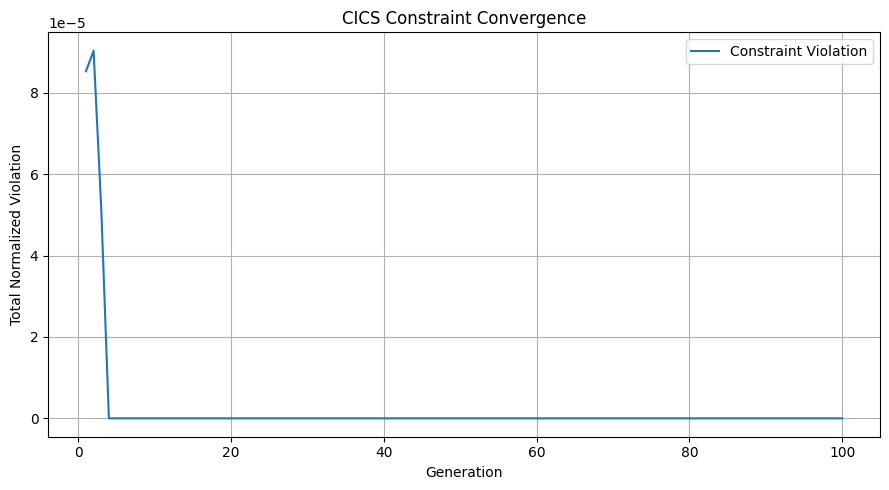

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math

# ==========================================
# 1. PARAMETERS
# ==========================================

N = 25                 # Number of nests
GENERATIONS = 100      # Maximum generations
PA = 0.25              # Discovery probability
DIM = 10               # Number of design variables

LOWER = -1.0
UPPER = 1.0

rng = np.random.default_rng(7)


# ==========================================
# 2. LEVY FLIGHT
# ==========================================

def levy_flight(size, beta=1.5):

    sigma = (
        math.gamma(1 + beta) *
        math.sin(math.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = rng.normal(0, sigma, size)
    v = rng.normal(0, 1, size)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


# ==========================================
# 3. AERODYNAMIC SURROGATE MODEL
# ==========================================

# NOTE:
# These are illustrative equations, NOT the
# paper's PMNS2D CFD aerodynamic calculations.

def aerodynamic_model(x):

    target = np.array([
        0.20, -0.10, 0.15, 0.05, -0.12,
        0.08, 0.10, -0.05, 0.04, -0.08
    ])

    weights = np.array([
        1.0, 1.2, 0.9, 1.1, 1.3,
        0.8, 1.0, 1.2, 0.9, 1.1
    ])

    # Objective: Minimize drag coefficient
    Cd = (
        0.018
        + 0.0008 * np.sum(weights * (x - target)**2)
        + 0.00015 * (x[0] - x[1])**2
    )

    # Lift coefficient
    Cl = (
        0.824
        + 0.035*x[0]
        - 0.025*x[1]
        + 0.018*x[2]
        - 0.012*x[3]
        + 0.008*np.sum(x[4:])
    )

    # Pitching moment coefficient
    Cm0 = -0.05

    Cm = (
        Cm0
        + 0.012*x[0]
        - 0.009*x[1]
        + 0.006*x[2]
        - 0.004*np.sum(x[3:])
    )

    # Cross-sectional area
    A0 = 0.08

    Area = (
        A0
        + 0.006*x[0]
        + 0.004*x[1]
        + 0.003*x[2]
        + 0.002*np.sum(x[3:])
    )

    # Constraint violations
    violations = np.array([

        # Cl = 0.824 (tolerance 0.002)
        max(abs(Cl - 0.824) - 0.002, 0),

        # Cm >= Cm0
        max(Cm0 - Cm, 0),

        # Area >= A0
        max(A0 - Area, 0)
    ])

    return Cd, violations, Cl, Cm, Area


# ==========================================
# 4. INITIALIZE CUCKOO NESTS
# ==========================================

nests = rng.uniform(
    LOWER, UPPER, (N, DIM)
)

evaluations = [
    aerodynamic_model(x) for x in nests
]

# Maximum constraint violation observed
max_violation = np.max(
    np.array([e[1] for e in evaluations]),
    axis=0
)


# ==========================================
# 5. CONSTRAINT HANDLING
# ==========================================

def feasible(evaluation):

    return np.all(evaluation[1] <= 1e-12)


def total_violation(evaluation):

    omega = 1 / np.maximum(
        max_violation, 1e-12
    )

    return np.dot(
        omega, evaluation[1]
    ) / np.sum(omega)


def rank_nests():

    feasible_exists = any(
        feasible(e) for e in evaluations
    )

    if feasible_exists:

        return sorted(
            range(N),
            key=lambda i: (
                (0, evaluations[i][0])
                if feasible(evaluations[i])
                else (1, total_violation(evaluations[i]))
            )
        )

    return sorted(
        range(N),
        key=lambda i: total_violation(evaluations[i])
    )


# ==========================================
# 6. CICS OPTIMIZATION
# ==========================================

best_fitness_history = []
best_violation_history = []

for generation in range(GENERATIONS):

    best_index = rank_nests()[0]
    best_nest = nests[best_index].copy()

    # Generate new solutions using Levy flight
    for i in range(N):

        step = levy_flight(DIM)

        new_nest = (
            nests[i]
            + 0.01 * step * (nests[i] - best_nest)
            + 0.005 * step * rng.normal(size=DIM)
        )

        new_nest = np.clip(
            new_nest, LOWER, UPPER
        )

        new_eval = aerodynamic_model(new_nest)

        max_violation[:] = np.maximum(
            max_violation, new_eval[1]
        )

        # Compare with a randomly selected nest
        j = rng.integers(N)

        old_eval = evaluations[j]

        new_feasible = feasible(new_eval)
        old_feasible = feasible(old_eval)

        # CICS dominance mechanism
        better = (
            (new_feasible and not old_feasible)
            or
            (
                new_feasible and old_feasible
                and new_eval[0] < old_eval[0]
            )
            or
            (
                not new_feasible and not old_feasible
                and total_violation(new_eval)
                < total_violation(old_eval)
            )
        )

        if better:

            nests[j] = new_nest
            evaluations[j] = new_eval

    # Discovery and replacement of worst nests
    count = max(1, round(PA * N))

    worst_indices = rank_nests()[-count:]

    for index in worst_indices:

        nests[index] = rng.uniform(
            LOWER, UPPER, DIM
        )

        evaluations[index] = aerodynamic_model(
            nests[index]
        )

        max_violation[:] = np.maximum(
            max_violation,
            evaluations[index][1]
        )

    # Find best solution
    best_index = rank_nests()[0]

    best_eval = evaluations[best_index]

    best_fitness_history.append(best_eval[0])

    best_violation_history.append(
        total_violation(best_eval)
    )

    # Generation-wise output
    print(
        f"Generation {generation + 1:3d} | "
        f"Fitness (Cd): {best_eval[0]:.8f} | "
        f"Violation: {total_violation(best_eval):.8f} | "
        f"Feasible: {feasible(best_eval)}"
    )


# ==========================================
# 7. FINAL OPTIMIZED SOLUTION
# ==========================================

best_index = rank_nests()[0]

best_solution = nests[best_index]

Cd, violations, Cl, Cm, Area = aerodynamic_model(
    best_solution
)

print("\n========== FINAL RESULTS ==========")

print("Optimized Design Variables:")

for i, value in enumerate(best_solution):

    print(f"x{i+1} = {value:.6f}")

print("\nMinimum Drag Coefficient:", Cd)

print("Lift Coefficient:", Cl)

print("Pitching Moment:", Cm)

print("Cross-sectional Area:", Area)

print("Constraint Violations:", violations)

print("Feasible Solution:", feasible(
    evaluations[best_index]
))


# ==========================================
# 8. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_fitness_history,
    marker='.',
    markersize=3,
    label='Best Drag Coefficient'
)

plt.xlabel("Generation")
plt.ylabel("Objective Function (Cd)")

plt.title(
    "CICS - Aerodynamic Shape Optimization"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 9. CONSTRAINT VIOLATION GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_violation_history,
    label='Constraint Violation'
)

plt.xlabel("Generation")
plt.ylabel("Total Normalized Violation")

plt.title("CICS Constraint Convergence")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
